# Notebook 4 of 6 — III.b Classification benchmark and optimisation
**Group 33** · Twelve algorithms from class under one protocol, a two-stage search (a random search over seven families, then a refinement of the best one), a soft-voting check, the decision threshold, and the score on the sealed holdout.

In [1]:
import json
import sys
import tempfile
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from joblib import Memory
from sklearn.base import clone
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import (AdaBoostClassifier, BaggingClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier,
                              RandomForestClassifier, VotingClassifier)
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import RandomizedSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier

sys.path.insert(0, str(Path.cwd().parent))   # project folder, which contains helpers/
import helpers.project_pipeline as pp

warnings.filterwarnings("ignore", message="Found unknown categories")
# Some sampled MLP settings stop at their iteration limit; that is part of what the search compares.
warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.width", 170)
BLUE, ORANGE, GREY = "#1779A8", "#C96A00", "#8C8C8C"
R = pp.RANDOM_STATE
OUTPUTS = Path("../outputs")    # fitted final model and its configuration (re-created by this notebook)
RESULTS = Path("../results")    # saved results of the stage-1 search (kept in the repository)
OUTPUTS.mkdir(exist_ok=True)

train, test, _ = pp.load_raw(pp.find_data_folder())
design = pp.development_split(train)
X, y, folds = design.X_dev, design.y_dev, design.folds

cache_folder = tempfile.TemporaryDirectory()
# Week 11: Pipeline(memory=...) caches the fitted preprocessing + selection of each fold, so the
# candidates of a search do not refit them again. Results are identical, only faster.
memory = Memory(cache_folder.name, verbose=0)

def pipeline(model, **prep_options):
    """The project pipeline: preprocessing -> vote feature selection (notebook 03) -> model."""
    return pp.make_pipeline(model, selector=pp.make_vote_selector(), memory=memory, **prep_options)

## 4.1 Protocol and metrics

- **Rows:** the 5,564 development purchases; the five yearly windows of notebook 01 (each trains on purchases more than 90 days before it opens). The sealed holdout is only scored after the final model is chosen, in Section 4.9.
- **Pipeline:** every model gets the same preprocessing (notebook 02) and vote selection (notebook 03), refitted in each window.
- **Comparison metric: ROC-AUC.** It does not depend on a threshold, so it compares how well models *rank* purchases. F1 at 0.5 and balanced accuracy at 0.5 are shown beside it, but F1 depends heavily on the threshold, which is chosen afterwards for the final model (Section 4.8).
- **Uncertainty:** mean and standard deviation over the five windows; differences between models are paired by window (a difference inside 2 × SEM is "inside the noise").
- **Selection rule, fixed in advance:** the final model is the candidate with the highest mean validation ROC-AUC; an ensemble is preferred over a single model only if it is better beyond the noise.

## 4.2 Baselines: what any model must beat

In [2]:
def baseline_scores(rule):
    rows = []
    for number, (_, score_at) in enumerate(folds, start=1):
        predicted = rule(X.iloc[score_at]).astype(int)
        s = pp.scores(y.iloc[score_at], predicted, threshold=0.5)
        rows.append({"fold": number, **s})
    return pd.DataFrame(rows).set_index("fold")

baselines = {
    "always 'repeat'": baseline_scores(lambda rows: np.ones(len(rows))),
    "rule: bought in the last 90 days": baseline_scores(lambda rows: rows["purchase_count_90d"].fillna(0) > 0),
}
display(pd.DataFrame({name: table[["ROC_AUC", "F1", "balanced_acc"]].mean() for name, table in baselines.items()}).T.round(4))

,ROC_AUC,F1,balanced_acc
always 'repeat',0.5000,0.7028,0.5000
rule: bought in the last 90 days,0.6613,0.6915,0.6613


Predicting "repeat" for everyone already gives F1 = 0.703 on these windows, with no ranking ability (AUC 0.5) and balanced accuracy 0.5. A sensible business rule ("customers who bought in the last 90 days will buy again") separates the classes somewhat (balanced accuracy 0.66) but scores a *lower* F1 (0.69) than predicting "repeat" for everyone. These are the reference points for every model below.

## 4.3 Benchmark: twelve algorithms from class with default settings

One representative of every family covered in class: linear (logistic regression, LDA), Bayesian (Gaussian naive Bayes), distance-based (KNN), a single tree, bagging (bagged trees, random forest, extra trees), boosting (AdaBoost, gradient boosting, histogram gradient boosting) and a neural network (MLP). Library defaults are used, except a larger iteration limit for logistic regression and the MLP so that they finish fitting.

In [3]:
# One algorithm per family seen in class, with library defaults (only a larger max_iter so that
# the iterative fits finish): week 6 linear, week 7 LDA and naive Bayes, week 8 KNN, week 9 tree,
# week 10 bagging and forests, week 11 boosting, week 12 MLP.
defaults = {
    "LogisticRegression": LogisticRegression(max_iter=5000, random_state=R),
    "LDA": LinearDiscriminantAnalysis(),
    "GaussianNB": GaussianNB(),
    "KNN": KNeighborsClassifier(),
    "DecisionTree": DecisionTreeClassifier(random_state=R),
    "Bagging": BaggingClassifier(random_state=R),
    "RandomForest": RandomForestClassifier(random_state=R, n_jobs=1),
    "ExtraTrees": ExtraTreesClassifier(random_state=R, n_jobs=1),
    "AdaBoost": AdaBoostClassifier(random_state=R),
    "GradientBoosting": GradientBoostingClassifier(random_state=R),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=R),
    "MLP": MLPClassifier(max_iter=1000, random_state=R),
}

default_scores, rows = {}, []
for name, model in defaults.items():
    start = time.time()
    default_scores[name], _ = pp.cross_validate_time(pipeline(model), X, y, folds)
    rows.append({"model": name, **pp.summarise(default_scores[name]),
                 "seconds (5 windows)": round(time.time() - start, 1)})
benchmark = pd.DataFrame(rows).set_index("model").sort_values("ROC_AUC mean", ascending=False)
display(benchmark.round(4))

,ROC_AUC mean,ROC_AUC std,F1 mean,F1 std,balanced_acc mean,balanced_acc std,seconds (5 windows)
model,,,,,,,
LogisticRegression,0.7897,0.0294,0.7359,0.0165,0.7158,0.0332,2.2
LDA,0.7844,0.0296,0.7279,0.0137,0.7095,0.0320,1.0
ExtraTrees,0.7797,0.0172,0.7259,0.0071,0.6973,0.0107,0.7
RandomForest,0.7789,0.0270,0.7357,0.0138,0.7054,0.0238,0.9
AdaBoost,0.7708,0.0277,0.7125,0.0176,0.7033,0.0236,0.6
GradientBoosting,0.7671,0.0372,0.7028,0.0370,0.6925,0.0369,1.8
HistGradientBoosting,0.7649,0.0326,0.7051,0.0299,0.6898,0.0253,0.5
GaussianNB,0.7433,0.0277,0.5094,0.1694,0.6098,0.0384,0.9
KNN,0.7341,0.0230,0.7081,0.0115,0.6753,0.0175,0.2


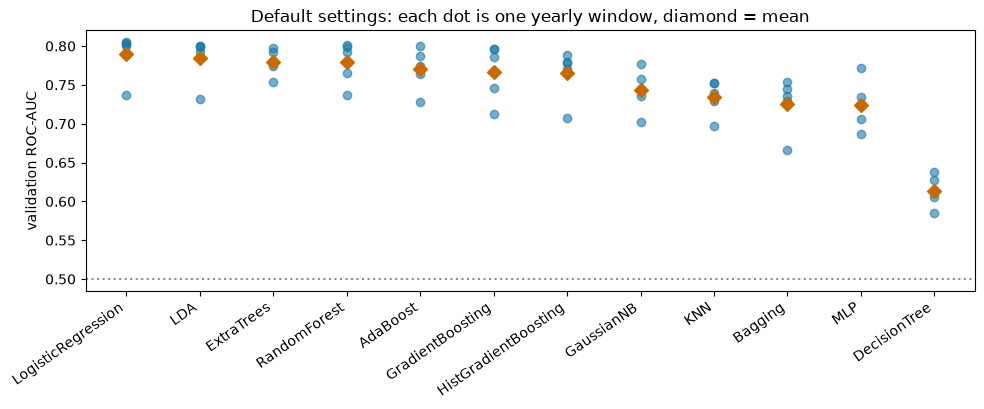

In [4]:
# ROC-AUC of every model in every window (one dot per window).
order = benchmark.index
fig, ax = plt.subplots(figsize=(10, 4.2))
for i, name in enumerate(order):
    values = default_scores[name]["ROC_AUC"]
    ax.scatter(np.full(len(values), i), values, color=BLUE, alpha=0.6)
    ax.scatter(i, values.mean(), color=ORANGE, marker="D", s=50, zorder=3)
ax.axhline(0.5, color=GREY, linestyle=":")
ax.set_xticks(range(len(order)), order, rotation=35, ha="right")
ax.set(ylabel="validation ROC-AUC", title="Default settings: each dot is one yearly window, diamond = mean")
plt.tight_layout()
plt.show()

- With default settings the **linear models rank first** (logistic regression 0.790, LDA 0.784), just ahead of extra trees (0.780) and random forest (0.779), then the boosting models (0.765–0.771).
- Models that memorise their training rows lose most: the unpruned **decision tree** (0.614) and **bagging** of ten unpruned trees (0.726). **KNN** with 5 neighbours (0.734) and the default **MLP** (0.725) are also weak, as weeks 8 and 12 predict for a small *k* and an unregularised network.
- **Gaussian naive Bayes** ranks reasonably (0.743) but its F1 at 0.5 collapses (0.51 ± 0.17): its probabilities are extreme because the many correlated history columns break its independence assumption (week 7).
- Every model except the single tree ranks purchases far better than the business rule, and the spread between windows (std 0.02–0.03) is as large as the gaps between the best models: the yearly windows differ more from each other than the top algorithms do. Paired comparisons are therefore needed.

## 4.4 Optimisation, stage 1: random search over seven families

The search tunes one model of every kind that can still improve: logistic regression (linear), KNN (distance), random forest and extra trees (bagging), AdaBoost and histogram gradient boosting (boosting), and the MLP (neural). KNN and the MLP are included despite weak defaults because their defaults are known to overfit (5 neighbours, an unregularised 100-unit layer), so the default ranking understates them.

The search spaces below are fixed before the search runs, and every family gets the same budget: as in class, **60 candidates** drawn at random without replacement (every combination when a space is smaller). With 60 draws there is about a 95 % chance of including at least one candidate from the best 5 % of the space, whatever its size (Bergstra & Bengio, 2012). Every candidate is scored on the same five windows with the whole pipeline refitted inside each, so selection and preprocessing never see validation rows. The rare-level merging of notebook 02 (`min_frequency`) is searched together with the model settings.

In [5]:
N_CANDIDATES = 60   # the class budget, the same for every family
merge = {"prep__columns__cat__encode__min_frequency": [1, 10, 30]}
search_spaces = {
    "LogisticRegression": (pp.base_model("LogisticRegression"), {
        "model__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10],
        "model__l1_ratio": [0, 0.25, 0.5, 0.75, 1],
        "model__class_weight": [None, "balanced"], **merge}),
    "KNN": (pp.base_model("KNN"), {
        "model__n_neighbors": [5, 11, 21, 31, 51, 75, 101, 151],
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2], **merge}),
    "RandomForest": (pp.base_model("RandomForest"), {
        "model__n_estimators": [100, 200, 300, 500],
        "model__max_depth": [None, 5, 8, 12, 16],
        "model__min_samples_leaf": [1, 2, 5, 10, 20],
        "model__max_features": ["sqrt", "log2", 0.3, 0.5],
        "model__criterion": ["gini", "entropy"],
        "model__class_weight": [None, "balanced"], **merge}),
    "ExtraTrees": (pp.base_model("ExtraTrees"), {
        "model__n_estimators": [100, 200, 300, 500],
        "model__max_depth": [None, 5, 8, 12, 16],
        "model__min_samples_leaf": [1, 2, 5, 10, 20],
        "model__max_features": ["sqrt", "log2", 0.3, 0.5],
        "model__criterion": ["gini", "entropy"],
        "model__class_weight": [None, "balanced"], **merge}),
    "AdaBoost": (pp.base_model("AdaBoost"), {
        "model__n_estimators": [100, 200, 300, 500],
        "model__learning_rate": [0.2, 0.4, 0.6, 0.8, 1.0], **merge}),
    "HistGradientBoosting": (pp.base_model("HistGradientBoosting"), {
        "model__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
        "model__max_iter": [50, 100, 200, 300, 500],
        "model__max_leaf_nodes": [7, 15, 31],
        "model__min_samples_leaf": [5, 10, 20, 50, 100],
        "model__l2_regularization": [0, 0.1, 1, 10],
        "model__max_depth": [None, 3, 5], **merge}),
    "MLP": (pp.base_model("MLP"), {
        "model__hidden_layer_sizes": [(8,), (16,), (32,), (64,), (16, 8), (32, 16)],
        "model__activation": ["relu", "tanh", "logistic"],
        "model__alpha": [1e-4, 1e-3, 1e-2, 0.1, 1, 3],
        "model__learning_rate_init": [1e-3, 3e-3, 1e-2],
        "model__batch_size": [64, 200],
        "model__early_stopping": [True, False], **merge}),
}
sizes = {name: int(np.prod([len(v) for v in space.values()])) for name, (_, space) in search_spaces.items()}
display(pd.DataFrame({"combinations": sizes,
                      "candidates tried": {name: min(N_CANDIDATES, size) for name, size in sizes.items()}}).T)

,LogisticRegression,KNN,RandomForest,ExtraTrees,AdaBoost,HistGradientBoosting,MLP
combinations,270,96,4800,4800,60,13500,3888
candidates tried,60,60,60,60,60,60,60


In [6]:
# Stage 1 takes about 5 minutes on 12 cores. Its results are also saved in results/stage1_search.json:
# RUN_SEARCH = False loads them instead of searching again (the final model is fitted with its
# selected settings in a separate cell anyway, Section 4.10).
RUN_SEARCH = True
SEARCH_FILE = RESULTS / "stage1_search.json"

if RUN_SEARCH:
    stage1 = {}
    for name, (model, space) in search_spaces.items():
        start = time.time()
        search = RandomizedSearchCV(pipeline(model), space, n_iter=min(N_CANDIDATES, sizes[name]),
                                    cv=folds, scoring="roc_auc", refit=False, n_jobs=-1, random_state=R)
        search.fit(X, y)
        stage1[name] = {"best_params": search.best_params_, "best_ROC_AUC": float(search.best_score_),
                        "candidates": min(N_CANDIDATES, sizes[name]),
                        "minutes": round((time.time() - start) / 60, 1)}
        print(f"{name}: best ROC-AUC {search.best_score_:.4f} in {stage1[name]['minutes']} min")
    RESULTS.mkdir(exist_ok=True)
    SEARCH_FILE.write_text(json.dumps(stage1, indent=2))

stage1 = json.loads(SEARCH_FILE.read_text())
tuning = pd.DataFrame([{"model": name, "candidates": result["candidates"],
                        "default ROC-AUC": default_scores[name]["ROC_AUC"].mean(),
                        "best ROC-AUC": result["best_ROC_AUC"], "minutes": result["minutes"]}
                       for name, result in stage1.items()]).set_index("model")
tuning["gain from tuning"] = tuning["best ROC-AUC"] - tuning["default ROC-AUC"]
display(tuning.sort_values("best ROC-AUC", ascending=False).round(4))
for name, result in stage1.items():
    print(f"{name:22s}", {key.replace("model__", "").replace("prep__columns__cat__encode__", ""): value
                          for key, value in result["best_params"].items()})

LogisticRegression: best ROC-AUC 0.7929 in 0.6 min


KNN: best ROC-AUC 0.7884 in 0.1 min


RandomForest: best ROC-AUC 0.7925 in 1.3 min


ExtraTrees: best ROC-AUC 0.7996 in 0.6 min


AdaBoost: best ROC-AUC 0.7860 in 1.1 min


HistGradientBoosting: best ROC-AUC 0.7897 in 0.4 min


MLP: best ROC-AUC 0.7946 in 0.7 min


,candidates,default ROC-AUC,best ROC-AUC,minutes,gain from tuning
model,,,,,
ExtraTrees,60,0.7797,0.7996,0.6,0.0199
MLP,60,0.7246,0.7946,0.7,0.0700
LogisticRegression,60,0.7897,0.7929,0.6,0.0032
RandomForest,60,0.7789,0.7925,1.3,0.0136
HistGradientBoosting,60,0.7649,0.7897,0.4,0.0248
KNN,60,0.7341,0.7884,0.1,0.0543
AdaBoost,60,0.7708,0.7860,1.1,0.0152


LogisticRegression     {'min_frequency': 1, 'l1_ratio': 0, 'class_weight': None, 'C': 0.03}
KNN                    {'min_frequency': 1, 'weights': 'distance', 'p': 1, 'n_neighbors': 101}
RandomForest           {'min_frequency': 10, 'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 'log2', 'max_depth': 12, 'criterion': 'gini', 'class_weight': None}
ExtraTrees             {'min_frequency': 10, 'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': None, 'criterion': 'entropy', 'class_weight': None}
AdaBoost               {'min_frequency': 1, 'n_estimators': 500, 'learning_rate': 0.2}
HistGradientBoosting   {'min_frequency': 1, 'min_samples_leaf': 50, 'max_leaf_nodes': 7, 'max_iter': 300, 'max_depth': 5, 'learning_rate': 0.03, 'l2_regularization': 10}
MLP                    {'min_frequency': 1, 'learning_rate_init': 0.001, 'hidden_layer_sizes': [8], 'early_stopping': False, 'batch_size': 200, 'alpha': 3, 'activation': 'relu'}


In [7]:
def as_params(params):
    """Settings read from JSON, which stores tuples (hidden_layer_sizes) as lists."""
    return {key: tuple(value) if isinstance(value, list) else value for key, value in params.items()}

settings = {name: as_params(result["best_params"]) for name, result in stage1.items()}
family = {name: name for name in settings}

def candidate_pipeline(name):
    """Unfitted project pipeline with the model of the candidate's family and its selected settings."""
    return pipeline(pp.base_model(family[name])).set_params(**settings[name])

# Re-score each tuned pipeline on the five windows to get its per-window scores and out-of-fold
# probabilities (identical folds and seeds, so the AUC matches the search).
tuned_scores, tuned_oof = {}, {}
for name in settings:
    tuned_scores[name], tuned_oof[name] = pp.cross_validate_time(candidate_pipeline(name), X, y, folds)
effect = pd.DataFrame([{"model": name, **pp.paired_delta(tuned_scores[name]["ROC_AUC"], default_scores[name]["ROC_AUC"])}
                       for name in settings]).set_index("model")
display(effect.round(4))

,mean_diff,SEM,wins,verdict
model,,,,
LogisticRegression,0.0032,0.0027,4/5,inside the noise
KNN,0.0543,0.0066,5/5,better
RandomForest,0.0136,0.0021,5/5,better
ExtraTrees,0.0199,0.0047,5/5,better
AdaBoost,0.0152,0.0029,5/5,better
HistGradientBoosting,0.0248,0.0021,5/5,better
MLP,0.0700,0.0153,5/5,better


- Tuning improves every family beyond the noise on all five windows, except **logistic regression**, whose default is already close to its best (`C = 0.03`, +0.003, inside the noise).
- The largest gains are for the models whose defaults overfit: **MLP +0.070** (one small layer of 8 units with a strong L2 penalty, `alpha = 3`), **KNN +0.054** (101 neighbours, distance-weighted, Manhattan distance), **histogram boosting +0.025** (7-leaf trees, slow learning rate, strong L2), **extra trees +0.020** and **random forest +0.014** (leaves of at least 5 purchases). AdaBoost gains +0.015 with 500 stumps and a small learning rate.
- The common thread is **strong regularisation**: the signal is modest and the yearly windows shift, so the settings that average more and fit less generalise best.
- The rare-level setting chosen is 1 or 10, never 30, which agrees with notebook 02.
- **Extra trees is the best family after stage 1** (0.7996). Each best score is the best of 60 candidates on the same windows, so it is slightly optimistic; the holdout (4.9) is the independent check.

## 4.5 Optimisation, stage 2: refining extra trees

Extra trees ranks first after stage 1. While developing the project we then refined it with several narrower random searches around its stage-1 settings, on the same five windows: larger leaves, a depth limit, a larger share of candidate columns per split, a minimum node size before splitting, and balanced class weights. Those exploratory searches are not repeated in this clean notebook; the two best configurations they produced are written out below and scored under exactly the same protocol as every other candidate. (They were found with `class_weight="balanced_subsample"`, which gives exactly the same model as `"balanced"` because extra trees do not bootstrap, so the simpler name is used.)

**What this stage changes about the holdout.** While refining, we also looked at the holdout and public Kaggle scores of the candidate configurations. The final choice still follows the rule of Section 4.1 (highest mean validation ROC-AUC), but because the shortlist was built with that information, the holdout score of the final model (Section 4.9) is slightly optimistic and should be read together with the window scores.

In [8]:
# The two best configurations found by the refinement searches (vote selection in front, as always).
refined = {
    "ExtraTrees refined A": {"prep__columns__cat__encode__min_frequency": 2, "model__n_estimators": 500,
                             "model__max_depth": 16, "model__min_samples_leaf": 10,
                             "model__max_features": 0.3, "model__criterion": "entropy",
                             "model__class_weight": "balanced"},
    "ExtraTrees refined B": {"prep__columns__cat__encode__min_frequency": 2, "model__n_estimators": 575,
                             "model__max_depth": 22, "model__min_samples_leaf": 6,
                             "model__min_samples_split": 24, "model__max_features": 0.25,
                             "model__criterion": "entropy", "model__class_weight": "balanced"},
}
for name, params in refined.items():
    settings[name], family[name] = params, "ExtraTrees"
    tuned_scores[name], tuned_oof[name] = pp.cross_validate_time(candidate_pipeline(name), X, y, folds)

stage2 = pd.DataFrame([{"candidate": "ExtraTrees (stage 1)" if name == "ExtraTrees" else name,
                        **pp.summarise(tuned_scores[name]),
                        **pp.paired_delta(tuned_scores[name]["ROC_AUC"], tuned_scores["ExtraTrees"]["ROC_AUC"])}
                       for name in ["ExtraTrees", *refined]]).set_index("candidate")
display(stage2.rename(columns={"mean_diff": "AUC vs stage 1"}).round(4))

,ROC_AUC mean,ROC_AUC std,F1 mean,F1 std,balanced_acc mean,balanced_acc std,AUC vs stage 1,SEM,wins,verdict
candidate,,,,,,,,,,
ExtraTrees (stage 1),0.7996,0.0233,0.7405,0.0097,0.7185,0.0218,0.0000,0.0000,0/5,identical
ExtraTrees refined A,0.7995,0.0265,0.7301,0.0151,0.7253,0.0224,-0.0000,0.0021,2/5,inside the noise
ExtraTrees refined B,0.8008,0.0236,0.7354,0.0124,0.7299,0.0195,0.0012,0.0010,4/5,inside the noise


Neither refined configuration is better than stage-1 extra trees beyond the noise: configuration B gains +0.0012 (ahead in 4 of 5 windows) and configuration A nothing. The refinement mostly confirms that the stage-1 settings were already close to what this data allows. Configuration B has the highest mean ROC-AUC of all candidates so far; Section 4.7 applies the selection rule to every candidate together.

## 4.6 Does combining the strongest models help? (soft voting)

Soft voting averages the probabilities of several tuned pipelines (week 11). It can only help if the members make different mistakes. The best candidate of each of the three best families is combined (one member per family, so the vote mixes model kinds), and the combination must beat the best single model beyond the noise to be chosen.

In [9]:
ranking = pd.Series({name: tuned_scores[name]["ROC_AUC"].mean() for name in tuned_scores}).sort_values(ascending=False)
best_single = ranking.index[0]
best_per_family = {}
for name in ranking.index:          # sorted by score, so the first candidate seen is the best of its family
    best_per_family.setdefault(family[name], name)
top3 = list(best_per_family.values())[:3]
vote_model = VotingClassifier([(name.replace(" ", "_"), candidate_pipeline(name)) for name in top3], voting="soft")
vote_scores, vote_oof = pp.cross_validate_time(vote_model, X, y, folds)
print("Members:", top3)
print("Soft vote ROC-AUC:", round(vote_scores["ROC_AUC"].mean(), 4), "| best single:", best_single, round(ranking.iloc[0], 4))
print("Vote vs best single:", {k: (round(v, 4) if isinstance(v, float) else v)
                              for k, v in pp.paired_delta(vote_scores["ROC_AUC"], tuned_scores[best_single]["ROC_AUC"]).items()})

Members: ['ExtraTrees refined B', 'MLP', 'LogisticRegression']
Soft vote ROC-AUC: 0.7987 | best single: ExtraTrees refined B 0.8008
Vote vs best single: {'mean_diff': np.float64(-0.002), 'SEM': np.float64(0.0037), 'wins': '2/5', 'verdict': 'inside the noise'}


The soft vote of refined extra trees B, the MLP and logistic regression reaches 0.7987, slightly *below* refined extra trees alone (−0.0020, inside the noise, ahead in 2 of 5 windows). The three members rely on the same customer-history signal and make similar mistakes, so averaging has little to cancel. Following the rule fixed in 4.1 (and the advice of weeks 6 and 10 to prefer the simpler model when a more complex one only matches it), the single model is kept.

## 4.7 Comparison of the candidates and choice of the final model

,stage,ROC_AUC mean,ROC_AUC std,F1 mean,F1 std,balanced_acc mean,balanced_acc std,AUC vs best,SEM,wins,verdict
candidate,,,,,,,,,,,
ExtraTrees refined B,2,0.8008,0.0236,0.7354,0.0124,0.7299,0.0195,0.0000,0.0000,0/5,identical
ExtraTrees,1,0.7996,0.0233,0.7405,0.0097,0.7185,0.0218,-0.0012,0.0010,1/5,inside the noise
ExtraTrees refined A,2,0.7995,0.0265,0.7301,0.0151,0.7253,0.0224,-0.0012,0.0018,2/5,inside the noise
soft vote (best of the 3 best families),vote,0.7987,0.0308,0.7387,0.0147,0.7254,0.0218,-0.0020,0.0037,2/5,inside the noise
MLP,1,0.7946,0.0326,0.7359,0.0174,0.7198,0.0244,-0.0062,0.0047,1/5,inside the noise
LogisticRegression,1,0.7929,0.0337,0.7447,0.0183,0.7229,0.0275,-0.0078,0.0054,1/5,inside the noise
RandomForest,1,0.7925,0.0278,0.7428,0.0128,0.7145,0.0225,-0.0083,0.0031,1/5,worse
HistGradientBoosting,1,0.7897,0.0318,0.7305,0.0174,0.7097,0.0276,-0.0110,0.0042,0/5,worse
KNN,1,0.7884,0.0307,0.7355,0.0089,0.7150,0.0185,-0.0123,0.0061,1/5,worse


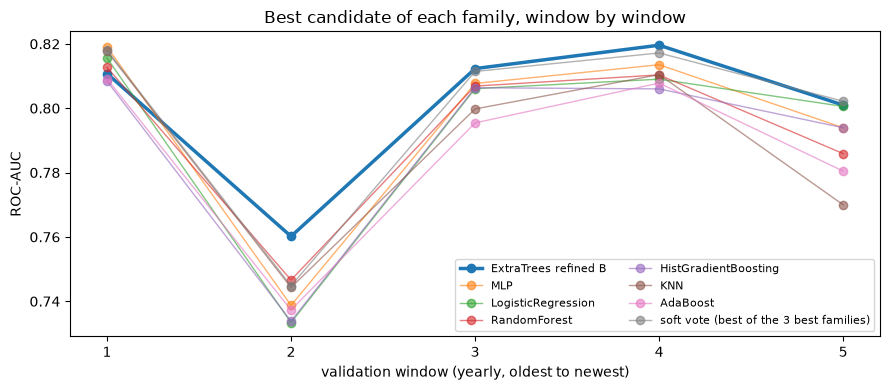

In [10]:
vote_name = "soft vote (best of the 3 best families)"
candidates = {**tuned_scores, vote_name: vote_scores}
reference = tuned_scores[best_single]["ROC_AUC"]
rows = []
for name, table in candidates.items():
    delta = pp.paired_delta(table["ROC_AUC"], reference)
    rows.append({"candidate": name, "stage": 2 if name in refined else (1 if name in stage1 else "vote"),
                 **pp.summarise(table), "AUC vs best": delta["mean_diff"],
                 "SEM": delta["SEM"], "wins": delta["wins"], "verdict": delta["verdict"]})
comparison = pd.DataFrame(rows).set_index("candidate").sort_values("ROC_AUC mean", ascending=False)
display(comparison.round(4))

# The best candidate of each family, plus the vote, window by window.
fig, ax = plt.subplots(figsize=(9, 4))
for name in [*best_per_family.values(), vote_name]:
    table = candidates[name]
    ax.plot(table.index, table["ROC_AUC"], marker="o", label=name,
            linewidth=2.5 if name == best_single else 1, alpha=1 if name == best_single else 0.6)
ax.set(xlabel="validation window (yearly, oldest to newest)", ylabel="ROC-AUC", xticks=range(1, 6),
       title="Best candidate of each family, window by window")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

- **Refined extra trees B** has the highest mean validation ROC-AUC (0.801 ± 0.024), so by the rule fixed in Section 4.1 it is the final model.
- Its lead is small: stage-1 extra trees (−0.001), refined A (−0.001), the soft vote (−0.002), the MLP (−0.006) and logistic regression (−0.008) are all inside the noise; random forest, histogram boosting, KNN and AdaBoost are behind beyond the noise. The data, not the algorithm, sets the ceiling at about 0.80 AUC.
- All candidates move together from window to window (window 2 is the hardest for everyone): this is the yearly drift seen in notebook 01, not a property of one model.

**Final model: `ExtraTreesClassifier`, refined configuration B** — 575 randomised trees with at least 6 purchases per leaf, at least 24 purchases in a node before it may split, a depth limit of 22, 25 % of the columns considered at each split, entropy criterion, balanced class weights, levels seen fewer than 2 times merged, vote feature selection in front. Stage-1 extra trees (300 trees, leaves of at least 5 purchases, √p columns per split) is practically tied, and tuned logistic regression is the natural simple fallback (−0.008, inside the noise, but behind in 4 of 5 windows).

## 4.8 Choosing the decision threshold

The model outputs a probability; the label needs a threshold (week 5). F1 rewards finding the repeat purchases, which are the majority, so its best threshold is usually below 0.5. The threshold is chosen on the **out-of-fold probabilities of the five windows** (no holdout row is used).

Best pooled threshold: 0.39 (F1 0.7518 vs 0.7349 at 0.50)
Best threshold in each window: [0.37, 0.3, 0.39, 0.53, 0.41]


,F1 at 0.50,F1 at 0.39,F1 floor,balanced acc. at 0.39
window,,,,
1,0.7400,0.7481,0.6909,0.6917
2,0.7302,0.7533,0.7407,0.6680
3,0.7358,0.7741,0.7070,0.7312
4,0.7523,0.7197,0.6543,0.6756
5,0.7188,0.7585,0.7213,0.7009


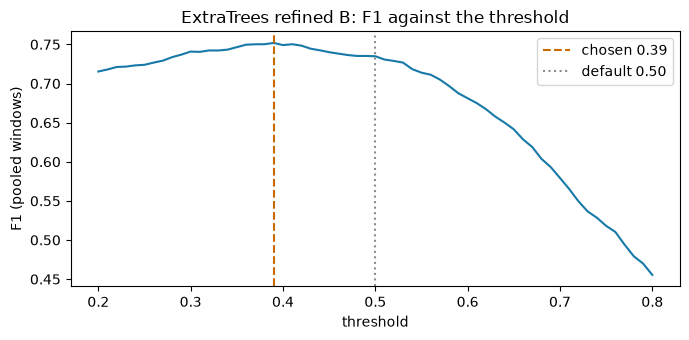

In [11]:
final_name = best_single
final_oof = tuned_oof[final_name]
scored = final_oof.notna()
curve = pp.f1_by_threshold(y[scored], final_oof[scored])
threshold = float(curve.idxmax())
per_window = [float(pp.f1_by_threshold(y.iloc[b], final_oof.iloc[b]).idxmax()) for _, b in folds]
print(f"Best pooled threshold: {threshold:.2f} (F1 {curve.max():.4f} vs {curve.loc[0.5]:.4f} at 0.50)")
print("Best threshold in each window:", per_window)

window_f1 = pd.DataFrame({
    "F1 at 0.50": [pp.scores(y.iloc[b], final_oof.iloc[b], 0.5)["F1"] for _, b in folds],
    f"F1 at {threshold:.2f}": [pp.scores(y.iloc[b], final_oof.iloc[b], threshold)["F1"] for _, b in folds],
    "F1 floor": [pp.scores(y.iloc[b], final_oof.iloc[b])["F1_floor"] for _, b in folds],
    f"balanced acc. at {threshold:.2f}": [pp.scores(y.iloc[b], final_oof.iloc[b], threshold)["balanced_acc"] for _, b in folds],
}, index=pd.Index(range(1, 6), name="window"))
display(window_f1.round(4))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(curve.index, curve.values, color=BLUE)
ax.axvline(threshold, color=ORANGE, linestyle="--", label=f"chosen {threshold:.2f}")
ax.axvline(0.5, color=GREY, linestyle=":", label="default 0.50")
ax.set(xlabel="threshold", ylabel="F1 (pooled windows)", title=f"{final_name}: F1 against the threshold")
ax.legend()
plt.tight_layout()
plt.show()

- Pooled over the five windows, F1 peaks at a threshold of **0.39** (0.7518, against 0.7349 at 0.50).
- The best threshold of single windows ranges from 0.30 to 0.53, so finer tuning would only fit noise: 0.39 improves F1 in four windows and costs some in window 4.
- At 0.39 the model beats the F1 floor in **every** window, by +0.013 to +0.067.
- A lower threshold means more purchases are labelled "repeat": recall of repeat purchases rises and fewer non-repeat purchases are detected. The cost is visible on the holdout below.

## 4.9 The sealed holdout

Everything above was compared on the development windows. The final procedure (chosen pipeline + threshold) is now refitted on **all development rows** and scored on the holdout: the last 12 months of `train.csv`, on which no model is ever fitted and with which the threshold is not chosen. Because the holdout was also consulted while refining extra trees (Section 4.5), read its score together with the window scores. Three references are scored on the same rows: stage-1 extra trees, selected without the holdout (with its own threshold, chosen on the windows in the same way), the always-"repeat" floor, and an untuned logistic regression with all columns and threshold 0.5, close to the homework approach.

In [12]:
final_pipeline = candidate_pipeline(final_name).fit(X, y)
holdout_probability = final_pipeline.predict_proba(design.X_hold)[:, 1]

# Reference selected without the holdout: stage-1 extra trees, with its own F1 threshold from the windows.
stage1_threshold = float(pp.f1_by_threshold(y[scored], tuned_oof["ExtraTrees"][scored]).idxmax())
stage1_probability = candidate_pipeline("ExtraTrees").fit(X, y).predict_proba(design.X_hold)[:, 1]

homework_like = pp.make_pipeline(LogisticRegression(max_iter=5000, random_state=R)).fit(X, y)
homework_probability = homework_like.predict_proba(design.X_hold)[:, 1]

holdout = pd.DataFrame({
    f"{final_name}, threshold {threshold:.2f}": pp.scores(design.y_hold, holdout_probability, threshold),
    f"{final_name}, threshold 0.50": pp.scores(design.y_hold, holdout_probability, 0.5),
    f"ExtraTrees stage 1, threshold {stage1_threshold:.2f}": pp.scores(design.y_hold, stage1_probability, stage1_threshold),
    "LogReg default, all columns, 0.50": pp.scores(design.y_hold, homework_probability, 0.5),
    "always 'repeat'": pp.scores(design.y_hold, np.ones(len(design.y_hold)), 0.5),
}).T.drop(columns="F1_floor")
display(holdout.round(4))
print(f"Holdout repeat rate: {design.y_hold.mean():.3f}; F1 floor: {2 * design.y_hold.mean() / (1 + design.y_hold.mean()):.4f}")
cv_estimate = window_f1[f"F1 at {threshold:.2f}"].mean()
print(f"Validation-window estimate of F1: {cv_estimate:.4f} | holdout F1: {holdout.iloc[0]['F1']:.4f}")
matrix = confusion_matrix(design.y_hold, (holdout_probability >= threshold).astype(int))
display(pd.DataFrame(matrix, index=["actual: no repeat", "actual: repeat"],
                     columns=["predicted: no repeat", "predicted: repeat"]))

,F1,ROC_AUC,balanced_acc,accuracy,precision,recall
"ExtraTrees refined B, threshold 0.39",0.8017,0.8162,0.7203,0.7466,0.7393,0.8756
"ExtraTrees refined B, threshold 0.50",0.7600,0.8162,0.7330,0.7318,0.7975,0.7258
"ExtraTrees stage 1, threshold 0.43",0.7941,0.8136,0.7056,0.7345,0.7266,0.8756
"LogReg default, all columns, 0.50",0.7626,0.7935,0.7214,0.7264,0.7743,0.7512
always 'repeat',0.7381,0.5000,0.5000,0.5849,0.5849,1.0000


Holdout repeat rate: 0.585; F1 floor: 0.7381
Validation-window estimate of F1: 0.7508 | holdout F1: 0.8017


,predicted: no repeat,predicted: repeat
actual: no repeat,174,134
actual: repeat,54,380


- On the 742 holdout purchases the final procedure reaches **ROC-AUC 0.816 and F1 0.802** (threshold 0.39), against a floor of 0.738 and 0.763 for the homework-style logistic regression (untuned, all columns, threshold 0.5).
- The holdout AUC agrees with the validation windows (0.801 ± 0.024). Stage-1 extra trees, chosen without the holdout, scores ROC-AUC 0.814 and F1 0.794 (its own threshold, 0.43) on the same rows: the refinement adds less than 0.01 F1 there too, so the optimism of the final score is small.
- The holdout F1 is higher than the window average (0.751) mostly because the holdout year has more repeat purchases (58.5 % against about 54 %), which raises the floor too: the **margin over the floor is similar** (+0.064 on the holdout, +0.048 on the windows). The same should be expected on Kaggle: the absolute F1 will follow the share of repeats in 2025–2026, and the margin over the floor should stay around +0.05.
- The threshold chosen for F1 finds **88 % of repeat purchases but only 56 % of non-repeat purchases** (174 of 308). At 0.50 the model would detect 74 % of non-repeats, with a lower F1 (0.760). For a retention campaign, which targets the non-repeats, a different operating point is better: this is studied in notebook 05.

## 4.10 Final model for deployment

The final model is the same pipeline, with the same settings and threshold, refitted on **all 6,469 usable labelled rows** (development, gap and holdout), so it learns from the most recent purchases before predicting 2025–2026. It is built directly from its selected settings in the cell below, so it does not depend on re-running the searches. Its configuration is saved as JSON (read by notebooks 05 and 06) and the fitted pipeline with `joblib` (week 2: save the model *with* its preprocessing).

In [13]:
config = {
    "model": family[final_name],
    "candidate": final_name,
    "best_params": settings[final_name],
    "threshold": threshold,
    "feature_selection": {"strategy": "vote (>= 2 of filter, RFE, L1)", "budget": pp.VOTE_BUDGET,
                          "redundancy": pp.VOTE_REDUNDANCY, "l1_C": pp.VOTE_L1_C},
    "validation_windows": {"ROC_AUC_mean": float(tuned_scores[final_name]["ROC_AUC"].mean()),
                           "ROC_AUC_std": float(tuned_scores[final_name]["ROC_AUC"].std()),
                           "F1_at_threshold_mean": float(cv_estimate)},
    "holdout": {k: float(v) for k, v in holdout.iloc[0].items()},
    "training_rows": int(len(design.X_all)),
}
# The final model is rebuilt from these settings (no search, no cache) and fitted on every usable row.
final_model = pp.final_pipeline(config).fit(design.X_all, design.y_all)
config["selected_columns"] = [str(c) for c in pp.selected_names(final_model)]
joblib.dump(final_model, OUTPUTS / "final_model.joblib")
(OUTPUTS / "final_config.json").write_text(json.dumps(config, indent=2))
print(f"Saved {final_name} trained on {len(design.X_all)} rows; it uses {len(config['selected_columns'])} columns; threshold {threshold:.2f}")
cache_folder.cleanup()

Saved ExtraTrees refined B trained on 6469 rows; it uses 63 columns; threshold 0.39
